# Wu et al. 2020 — AML · 04 · EMT-TF expression

Unconditional final step. Score a broad EMT-TF candidate panel (Snail / Zeb / Twist / **FOXC** / **PRRX** families — TFs only, never VIM), gate on **detectable** expression, and overlay thresholded expressers as a categorical layer on a grey manifold. Gate 2 was GO (non-branching); Gate 3 is NA, so this is the last notebook (numbered 04).

In [1]:
import os, sys, glob
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*6))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
os.makedirs(pth_fig, exist_ok=True)

**Load `signatures.h5ad`; use the house linear layout.**

In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'signatures.h5ad'))
adata.obsm['X_umap'] = adata.obsm['X_umap_lin']   # house linear layout
t = adata.obs['t'].values; tn = (t-t.min())/(t.max()-t.min())
print('cells:', adata.shape[0], '| pseudotime range', round(t.min(),2), '->', round(t.max(),2))

cells: 96881 | pseudotime range 0.0 -> 7.32


**Screen the EMT-TF panel, gated on detectable expression.** Fraction expressing, early/late means, and Spearman correlation with pseudotime. On this shallow Microwell-seq panel the FOXC/PRRX/SNAI2/TWIST1 factors are absent from the measured genes and SNAI1/ZEB1/TWIST2 are below the 3% detection floor; only ZEB2 clears it — an honest single-factor readout, not a panel-width omission.

In [4]:
panel = ['SNAI1','SNAI2','ZEB1','ZEB2','TWIST1','TWIST2','FOXC1','FOXC2','PRRX1','PRRX2']
present = [g for g in panel if g in adata.var_names]
print('candidate EMT-TFs present in data:', present)
print('candidate EMT-TFs absent from panel:', [g for g in panel if g not in adata.var_names])
early = tn <= np.quantile(tn, 1/3); late = tn >= np.quantile(tn, 2/3)
X = adata[:,present].X; X = X.toarray() if hasattr(X,'toarray') else np.asarray(X)
rows = []
for j,g in enumerate(present):
    x = X[:,j]; rho,p = spearmanr(tn, x)
    rows.append((g, round((x>0).mean(),3), round(x[early].mean(),3), round(x[late].mean(),3), round(rho,3)))
df = pd.DataFrame(rows, columns=['TF','frac_expr','mean_early','mean_late','rho_vs_t'])
df['end'] = np.where(df.mean_early > df.mean_late, 'EARLY(root)', 'LATE(terminus)')
df = df.sort_values('rho_vs_t')
print(df.to_string(index=False))
DET = 0.03
ok = df[df.frac_expr > DET]
shown = ok.TF.tolist()
print(f'\nEMT-TFs above the {DET:.0%} detection floor:', shown)

candidate EMT-TFs present in data: ['SNAI1', 'ZEB1', 'ZEB2', 'TWIST2']
candidate EMT-TFs absent from panel: ['SNAI2', 'TWIST1', 'FOXC1', 'FOXC2', 'PRRX1', 'PRRX2']
    TF  frac_expr  mean_early  mean_late  rho_vs_t            end
  ZEB2      0.051       0.033      0.034    -0.009 LATE(terminus)
 SNAI1      0.000       0.000      0.000    -0.003 LATE(terminus)
  ZEB1      0.005       0.003      0.003    -0.003 LATE(terminus)
TWIST2      0.000       0.000      0.000     0.003 LATE(terminus)

EMT-TFs above the 3% detection floor: ['ZEB2']


**Deliverable — `expression.pdf`.** Categorical overlay of thresholded ZEB2 expressers (upper quartile among expressers) on the grey manifold — set display cutoff, not a continuous colormap.

overlay thresholds (upper quartile among expressers): {'ZEB2': 0.785} | cells shown: {'ZEB2': 1241}
ZEB2: 5.1% expressing; 1241 shown (upper quartile), mean pseudotime of shown cells = 0.58 (all cells = 0.51)
saved expression.pdf


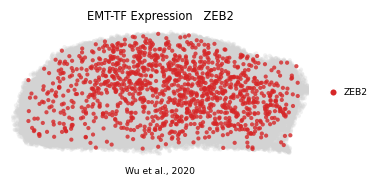

In [5]:
def _vec(g):
    x = adata[:,g].X
    return x.toarray().ravel() if hasattr(x,'toarray') else np.asarray(x).ravel()
xl = adata.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
palette = ['tab:red','tab:blue','tab:green','tab:orange']
thr = {}; sel = {}
for g in shown:
    v = _vec(g); pos = v[v>0]; thr[g] = float(np.quantile(pos, 0.75)) if pos.size else 0.0
    sel[g] = v > thr[g]
colors = {g: palette[i] for i,g in enumerate(shown)}
order = sorted(shown, key=lambda g: -int(sel[g].sum()))
print('overlay thresholds (upper quartile among expressers):', {g: round(thr[g],3) for g in shown},
      '| cells shown:', {g: int(sel[g].sum()) for g in shown})
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(adata, size=30, alpha=.3, frameon=False, show=False, ax=ax, na_color='lightgray')
for g in order:
    ap = adata[sel[g]].copy()
    sc.pl.umap(ap, na_color=colors[g], size=30, alpha=.8, frameon=False, show=False, ax=ax)
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
lbl = ' · '.join(f'{g}' for g in order)
ax.set_title(f'EMT-TF Expression   {lbl}', size=7.5)
from matplotlib.lines import Line2D
handles = [Line2D([0],[0], marker='o', color='w', markerfacecolor=colors[g], markersize=5, label=g) for g in order]
ax.legend(handles=handles, frameon=False, loc='center left', bbox_to_anchor=(1.02,.5), fontsize=6, handletextpad=.2)
ax.text(.5,-.14,'Wu et al., 2020', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'expression.pdf'), bbox_inches='tight')
for g in order:
    m = sel[g]
    print(f'{g}: {(_vec(g)>0).mean()*100:.1f}% expressing; {int(m.sum())} shown (upper quartile), '
          f'mean pseudotime of shown cells = {tn[m].mean():.2f} (all cells = {tn.mean():.2f})')
print('saved expression.pdf')